# CSC311 project proposal: data exploration
This notebook consolidates the team's Q2–Q7 categorical analysis and Q8–Q12 word counts, adds Q1/Q12 numerical and missing-value exploration, and verifies the repaired split. **No models are trained or selected here.**

Run all cells from the repository root or `analysis/`. Select the project `.venv` Python kernel. Dependencies are listed in `analysis/requirements.txt`. Outputs are saved under `analysis/out/proposal/`; figures and tables also appear inline.

The assignment requests a complete exploration draft (at most two report pages) plus code. This notebook is the supporting analysis, not a two-page submission. Sources: `ProjectInstructions/CSC311_Project_Instructions.pdf`, section 3.3/Table 4, and the report template, section 2/Appendix A.

**Data boundary:** only `data/splits/train.csv` is explored. Held-out files are read only for ID/label integrity and fixed preprocessing transformation; their feature distributions and performance are not examined. There are 290 respondents with three sport responses each, not 870 independent respondents. `id` and `label` are excluded from model inputs.

In [3]:
from pathlib import Path
import sys, json, hashlib, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'analysis/survey_common.py').exists())
sys.path.insert(0, str(ROOT / 'analysis'))
sys.path.insert(0, str(ROOT / 'data_preprocessing'))
from survey_common import CLASSES, QUALITY_SPECS, MULTI_VOCAB_BY_Q, LIKERT_SCALE, feature_quality
from categorical_stats import analyse_categorical
from text_word_counts import count_words
from encode_all import clean, parse_payment, raw_headers, encode_structured
OUT = ROOT / 'analysis/out/proposal'
OUT.mkdir(parents=True, exist_ok=True)
train = pd.read_csv(ROOT / 'data/splits/train.csv', dtype=str, keep_default_na=False)
train = raw_headers(train)
plt.rcParams.update({'axes.prop_cycle': plt.cycler(color=['#2ca02c', '#1f77b4', '#ff7f0e']), 'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
def table(frame, name):
    frame.to_csv(OUT / (name + '.csv'), index=True)
    display(frame.round(3))
def figure(name):
    plt.tight_layout()
    plt.savefig(OUT / (name + '.png'), dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
print('Exploration rows:', len(train), '| respondents:', train.id.nunique())

Exploration rows: 606 | respondents: 202


## 1. Canonical split and repair
The original `analysis/make_splits.py` and `encode_all.py --input` used different splitting algorithms. Before repair, 132 respondents changed assignment between their manifests; 28 original test respondents appeared in encoded training, and 30 original training respondents appeared in encoded test.

The repair preserves **all existing raw split files** and rebuilds `data/encoded/` using `analysis/rebuild_encoded.py`. That script fits TF-IDF and payment imputation on canonical training only, then transforms validation/test. It stages outputs before replacing generated files. It does not run the alternative splitter.

The following cell verifies the repaired outputs without rebuilding them on every notebook run. To rebuild explicitly: `python analysis/rebuild_encoded.py`. The original raw partition is the source of truth. Rebuilding fixes current artifacts; it cannot undo any previous human use of a different held-out partition.

In [4]:
paths = {'train': 'train.csv', 'validation': 'val.csv', 'test': 'test.csv'}
manifest = pd.read_csv(ROOT / 'data/splits/id_to_split.csv', dtype=str)
manifest['split'] = manifest['split'].replace({'val': 'validation'})
encoded_manifest = pd.read_csv(ROOT / 'data/encoded/split_manifest.csv', dtype=str)
assert manifest.set_index('id')['split'].sort_index().equals(encoded_manifest.set_index('id')['split'].sort_index())
summary = json.loads((ROOT / 'data/encoded/encoding_summary.json').read_text())
assert summary['inputs']['mode'] == 'existing_splits'
seen = set()
rows = []
for split, filename in paths.items():
    path = ROOT / 'data/splits' / filename
    meta = pd.read_csv(path, dtype=str, usecols=['id', 'label'])
    encoded_meta = pd.read_csv(ROOT / f'data/encoded/{split}_encoded.csv', dtype=str, usecols=['id', 'label'])
    assert meta.equals(encoded_meta)
    ids = set(meta.id)
    assert not seen.intersection(ids)
    seen.update(ids)
    assert meta.groupby('id')['label'].agg(set).map(lambda x: x == set(CLASSES)).all()
    assert meta.groupby('id').size().eq(3).all()
    # Legacy encoding summaries hashed Windows CRLF bytes; accept only newline-equivalent text.
    source = path.read_bytes().replace(b'\r\n', b'\n')
    source_hashes = {hashlib.sha256(data).hexdigest() for data in
                     (source, source.replace(b'\n', b'\r\n'))}
    assert summary['inputs']['files'][split]['sha256'] in source_hashes
    rows.append({'split': split, 'responses': len(meta), 'respondents': len(ids), **meta.label.value_counts().to_dict()})
table(pd.DataFrame(rows).set_index('split'), 'split_integrity')
print('PASS: disjoint respondent groups, matching manifests, row order, labels, and source hashes.')

,responses,respondents,Soccer,Baseball,Basketball
split,,,,,
train,606,202,202,202,202
validation,132,44,44,44,44
test,132,44,44,44,44


PASS: disjoint respondent groups, matching manifests, row order, labels, and source hashes.


The approximately 70/15/15 split contains 606/132/132 responses and 202/44/44 people. Class counts are equal within each split, so resampling for class imbalance is not indicated. Grouping avoids learning a respondent's writing style from training and encountering that same person in evaluation. Validation is reserved for model selection; the local test set is reserved for final evaluation. The course's hidden staff test set is separate and may differ from student responses.

## 2. Inventory and consistent missing-value accounting
There are **12 questions**: Q1 numeric (0–10, including decimals); Q2–Q4 ordinal Likert; Q5–Q7 multi-select; Q8–Q11 free text; Q12 free text representing a monetary amount.

We report mutually exclusive literal blanks, recognized missing markers, and invalid/unparseable responses. Counts use the actual encoder's `clean` and `parse_payment` rules. For text, a response such as “none” can be meaningful (e.g. no associated song), so we separately flag the older analysis's semantic non-answers rather than silently deleting them. English-alphabet token filtering can also produce an empty vector for a nonmissing response. Neither case is equated with a literal blank.

Q12 uses a numeric-only policy: spelled-out numbers/unwillingness and ambiguous answers may be imputed. This limitation is quantified below; it is not described as an ability to understand all valid monetary answers.

,type,blank_n,marker_n,invalid_n,unusable_n,unusable_pct,usable_n
question,,,,,,,
Q1,scale,7,0,0,7,1.155,599
Q2,likert,8,0,0,8,1.320,598
Q3,likert,7,0,0,7,1.155,599
Q4,likert,8,0,0,8,1.320,598
Q5,multi,7,0,0,7,1.155,599
Q6,multi,7,0,0,7,1.155,599
Q7,multi,7,0,0,7,1.155,599
Q8,text,9,3,0,12,1.980,594
Q9,text,7,0,0,7,1.155,599


label,Soccer,Baseball,Basketball
Q1,0.495,1.485,1.485
Q2,0.495,1.485,1.980
Q3,0.495,1.485,1.485
Q4,0.495,1.485,1.980
Q5,0.495,1.485,1.485
Q6,0.495,1.485,1.485
Q7,0.495,1.485,1.485
Q8,0.495,1.980,3.465
Q9,0.495,1.485,1.485
Q10,1.980,6.436,7.426


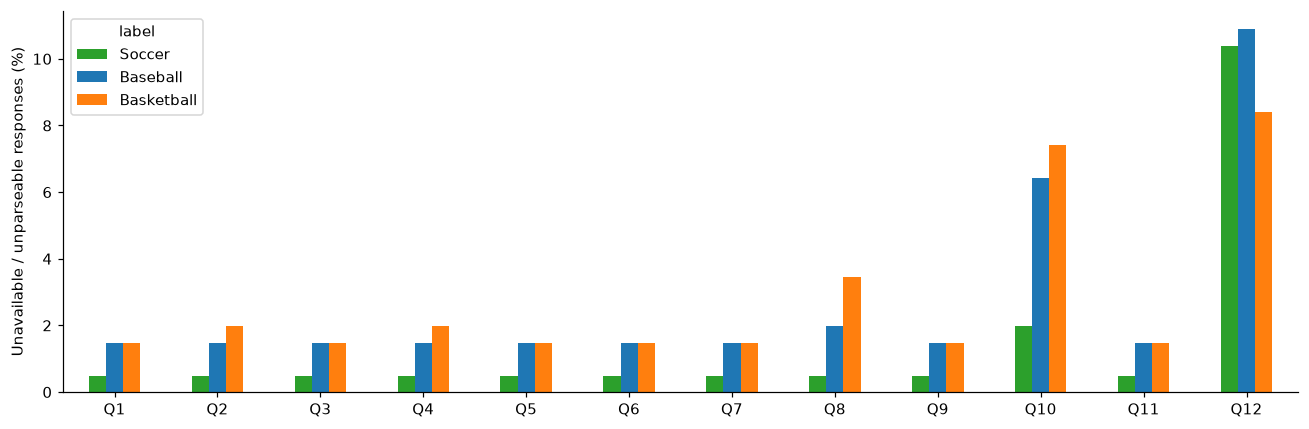

Largest class gap in unavailable rates:


Q10    5.445545
Q8     2.970297
Q12    2.475248
Q2     1.485149
Q4     1.485149
dtype: float64

In [5]:
missing_masks = {}
quality_rows = []
for q, name, prefix, kind in QUALITY_SPECS:
    col = next(col for col in train if col.startswith(prefix))
    raw = train[col].str.strip()
    normalized = raw.map(clean)
    blank = raw.eq('')
    marker = normalized.eq('') & ~blank
    absent = blank | marker
    if kind == 'scale':
        numeric = pd.to_numeric(normalized, errors='coerce')
        invalid = ~absent & (~numeric.between(0, 10) | ~np.isfinite(numeric))
    elif kind == 'likert':
        invalid = ~absent & ~normalized.isin([s.lower() for s in LIKERT_SCALE])
    elif kind == 'multi':
        allowed = {s.lower() for s in MULTI_VOCAB_BY_Q[q]}
        invalid = ~absent & normalized.map(lambda s: not {x.strip() for x in s.split(',') if x.strip()} or bool({x.strip() for x in s.split(',') if x.strip()} - allowed))
    elif kind == 'price':
        invalid = ~absent & raw.map(lambda s: parse_payment(s)[0] is None)
    else:
        invalid = pd.Series(False, index=train.index)
    unusable = absent | invalid
    missing_masks[q] = unusable
    quality_rows.append({'question': q, 'type': kind, 'blank_n': int(blank.sum()), 'marker_n': int(marker.sum()), 'invalid_n': int(invalid.sum()), 'unusable_n': int(unusable.sum()), 'unusable_pct': 100*unusable.mean(), 'usable_n': int((~unusable).sum())})
quality = pd.DataFrame(quality_rows).set_index('question')
table(quality, 'missing_values')
by_class = pd.DataFrame({q: mask.groupby(train.label).mean().reindex(CLASSES)*100 for q, mask in missing_masks.items()}).T
table(by_class, 'missing_values_by_class_pct')
by_class.plot.bar(figsize=(12, 4), ylabel='Unavailable / unparseable responses (%)', rot=0)
figure('missing_values_by_class')
print('Largest class gap in unavailable rates:')
display((by_class.max(axis=1)-by_class.min(axis=1)).sort_values(ascending=False).head())

Missingness may reflect unfamiliarity, lack of an association, or reluctance to give a price; these are hypotheses, not established causes. Class-wise rates above test descriptively whether missingness may carry signal. Missing indicators preserve that possibility without claiming causality. Because responses are grouped by person, ordinary independent-row significance tests are not used here.

**Handling policy:** retain responses, distinguish missing from unselected multi-hot options, and learn all replacement values from training only. Existing encoding leaves Q1–Q7 missing; a downstream modelling pipeline must impute numeric/Likert values (training median) and multi-hot values (training mode), with question-level missing flags. That planned step is not yet applied to these CSVs. Text uses empty vectors plus missing flags. Q12 currently uses the training mean plus an imputation flag; the numerical analysis below assesses this choice. Preprocessing must be fitted again inside each training fold if cross-validation is introduced.

## 3. Existing Q2–Q7 categorical exploration
Reuse the team's statistics and plot generator. Likert plots use scores 1–5; the encoder uses `(score - 1)/4`, so means and variances are on different scales. A binary option's mean is its selection rate and its variance is determined by that rate; they are meaningful, not undefined.

,question,kind,class_,n,mean,var,sd,cramers_v,eta2
0,Q2 strategy dependence,single_ordinal,Soccer,201,3.965,0.684,0.827,0.247,0.072
1,Q2 strategy dependence,single_ordinal,Baseball,199,3.412,1.122,1.059,0.247,0.072
2,Q2 strategy dependence,single_ordinal,Basketball,198,3.904,0.564,0.751,0.247,0.072
3,Q2 strategy dependence,single_ordinal,ALL,598,3.761,0.849,0.921,0.247,0.072
4,Q3 injury risk,single_ordinal,Soccer,201,3.801,0.840,0.917,0.309,0.163
5,Q3 injury risk,single_ordinal,Baseball,199,2.899,1.010,1.005,0.309,0.163
6,Q3 injury risk,single_ordinal,Basketball,199,3.789,0.905,0.951,0.309,0.163
7,Q3 injury risk,single_ordinal,ALL,599,3.497,1.093,1.046,0.309,0.163
8,Q4 individual brilliance,single_ordinal,Soccer,201,2.930,1.175,1.084,0.248,0.115
9,Q4 individual brilliance,single_ordinal,Baseball,199,3.804,1.037,1.018,0.248,0.115


,question,kind,option,n,selected,selected_Soccer,selected_Baseball,selected_Basketball,n_Soccer,n_Baseball,n_Basketball,cramers_v,pct_Soccer,pct_Baseball,pct_Basketball
0,Q5 venue,multi_indicator,Indoor facility,599,373,129,51,193,201,199,199,0.601,64.179,25.628,96.985
7,Q6 season,multi_indicator,Winter,599,143,16,12,115,201,199,199,0.561,7.960,6.030,57.789
16,Q7 music type,multi_indicator,Hip-hop or rap,599,290,80,43,167,201,199,199,0.523,39.801,21.608,83.920
13,Q7 music type,multi_indicator,Latin,599,92,82,9,1,201,199,199,0.503,40.796,4.523,0.503
5,Q5 venue,multi_indicator,At home or nearby,599,258,96,30,132,201,199,199,0.427,47.761,15.075,66.332
17,Q7 music type,multi_indicator,Country,599,80,9,64,7,201,199,199,0.390,4.478,32.161,3.518
3,Q5 venue,multi_indicator,Community recreation facility,599,431,152,101,178,201,199,199,0.356,75.622,50.754,89.447
12,Q7 music type,multi_indicator,Electronic or dance,599,130,73,24,33,201,199,199,0.256,36.318,12.060,16.583
2,Q5 venue,multi_indicator,School or university facility,599,518,175,151,192,201,199,199,0.246,87.065,75.879,96.482
19,Q7 music type,multi_indicator,No particular type,599,118,34,65,19,201,199,199,0.242,16.915,32.663,9.548


,question,feature,value,n_total,n_Soccer,n_Baseball,n_Basketball
0,Q5 venue,selection_count,0,0,0,0,0
1,Q5 venue,selection_count,1,51,15,30,6
2,Q5 venue,selection_count,2,55,17,34,4
3,Q5 venue,selection_count,3,81,24,53,4
4,Q5 venue,selection_count,4,109,32,52,25
5,Q5 venue,selection_count,5,104,42,17,45
6,Q5 venue,selection_count,6,151,43,13,95
7,Q5 venue,selection_count,7,48,28,0,20
8,Q6 season,selection_count,0,0,0,0,0
9,Q6 season,selection_count,1,91,42,31,18


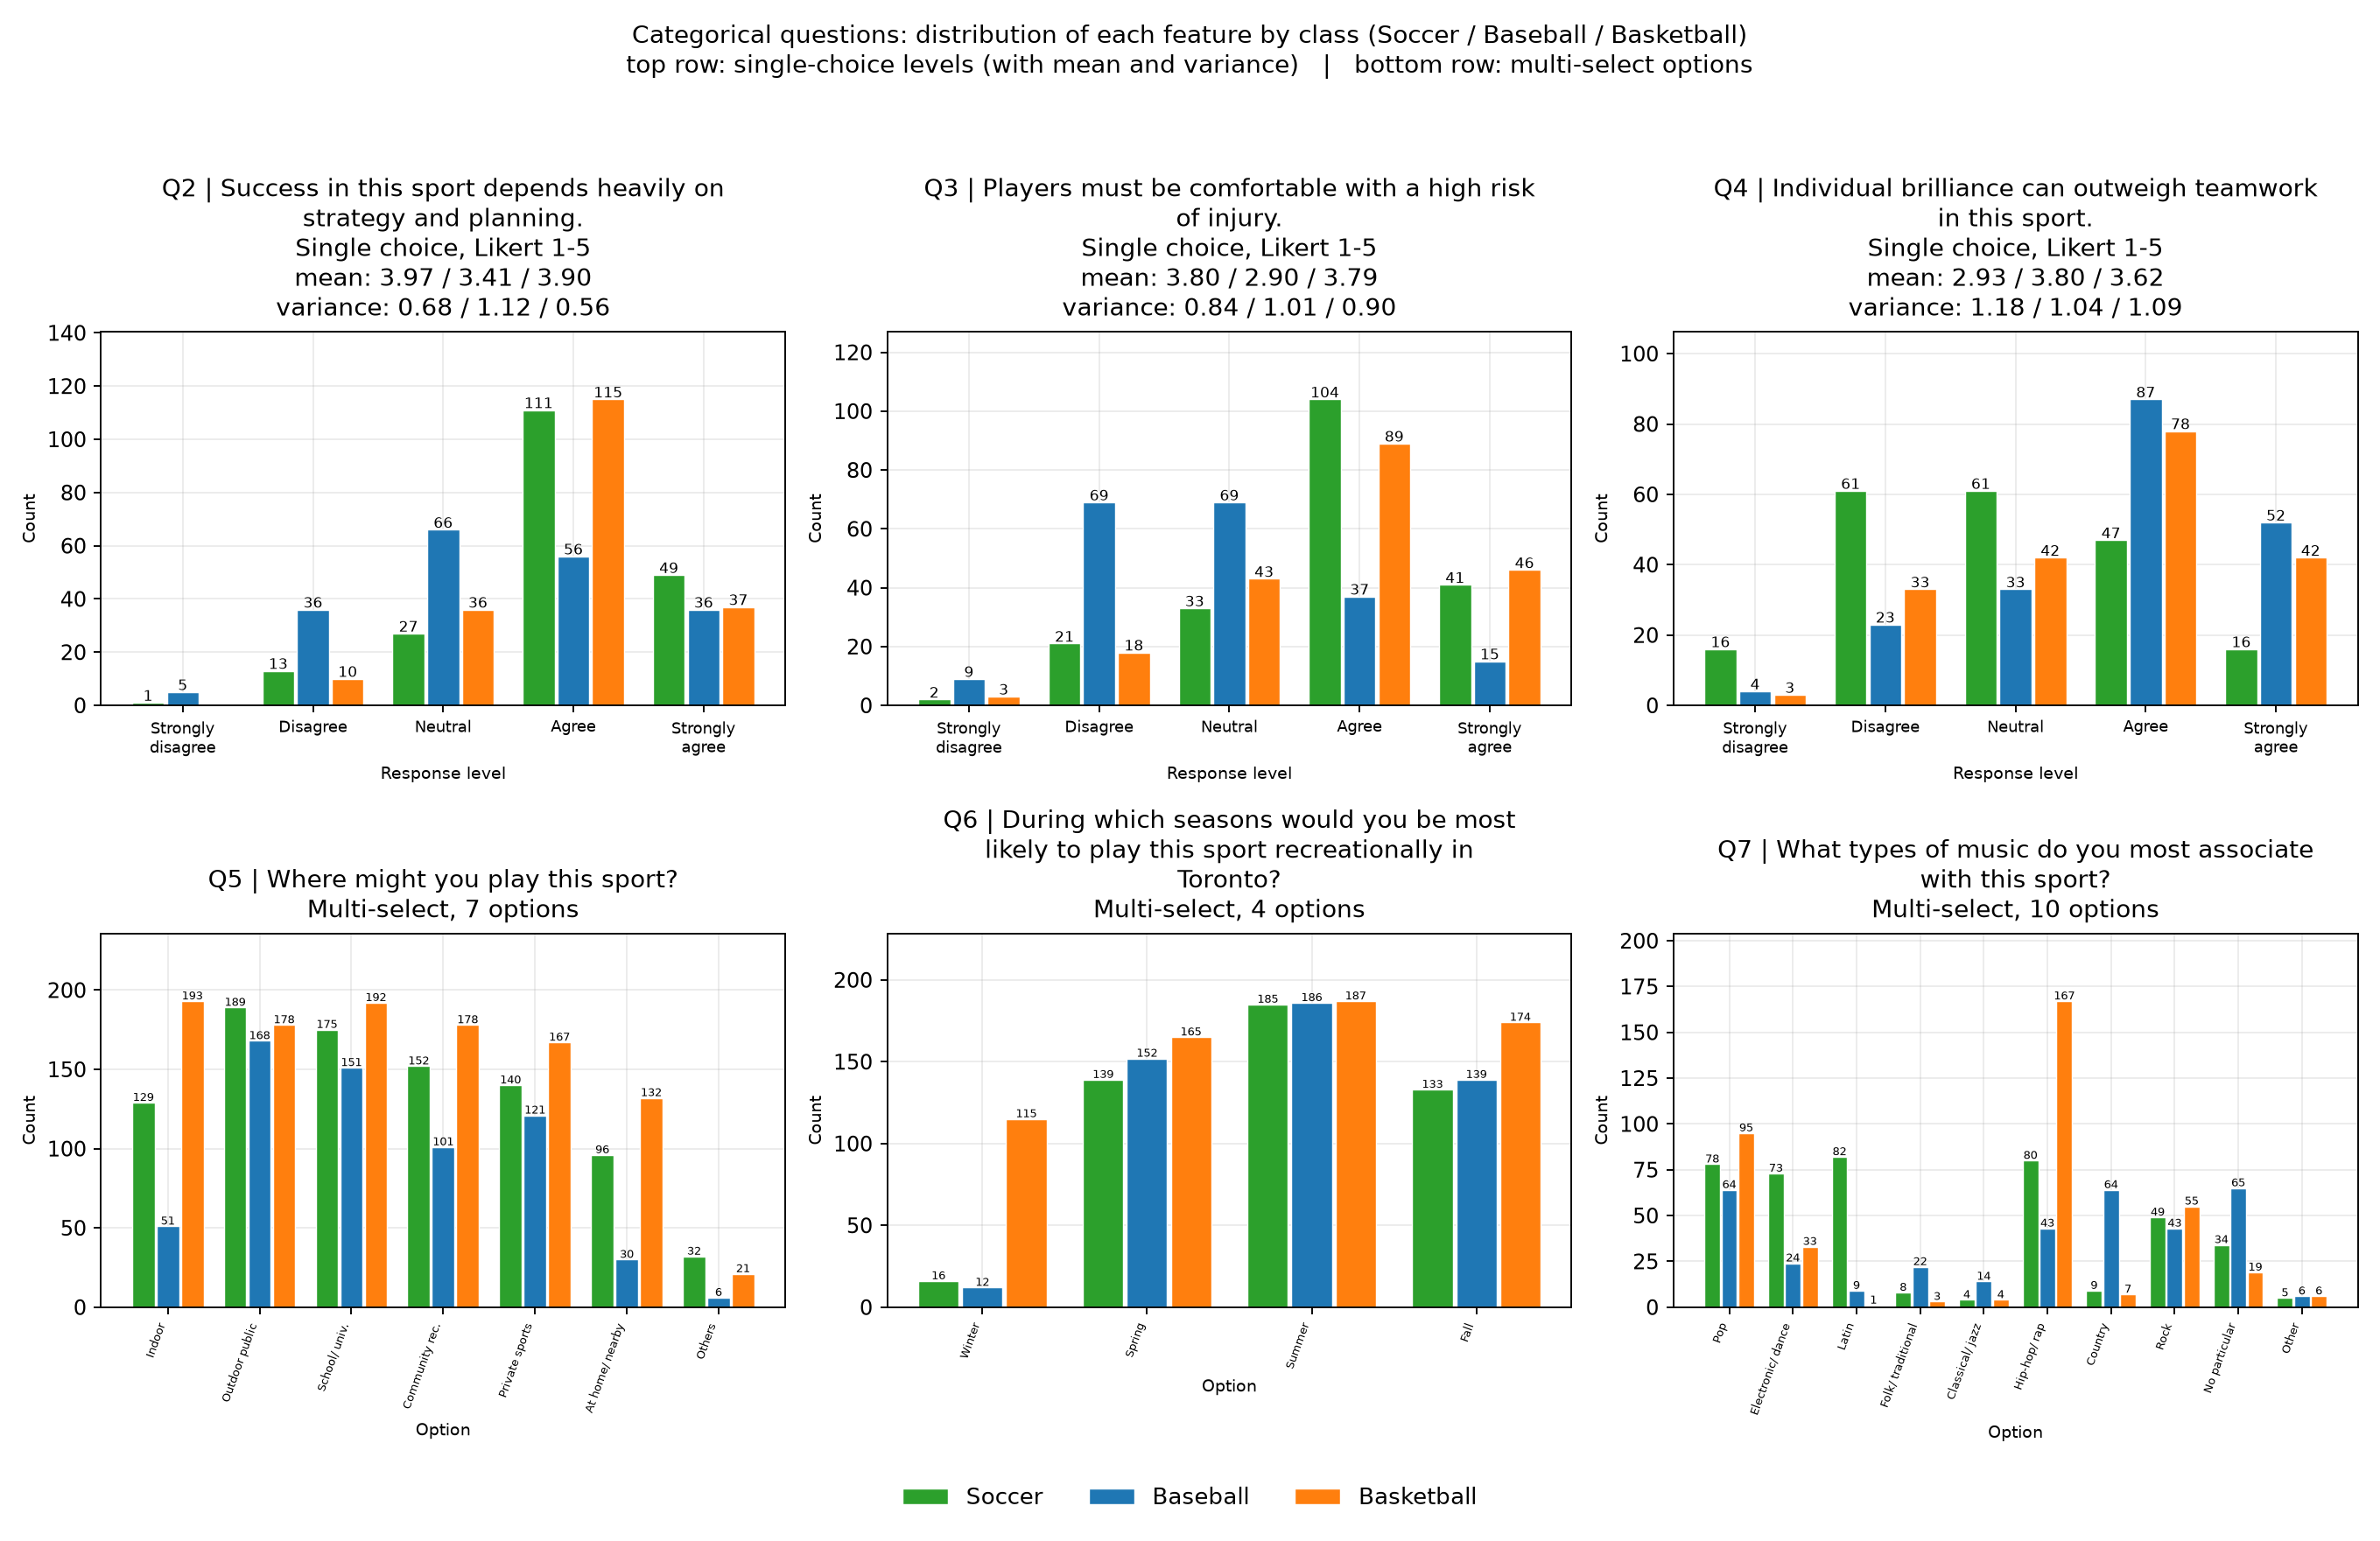

,feature,cramers_v,eta_squared,kind
3,Q5 venue - Indoor facility,0.601,NaN,indicator
10,Q6 season - Winter,0.561,NaN,indicator
19,Q7 music type - Hip-hop or rap,0.523,NaN,indicator
16,Q7 music type - Latin,0.503,NaN,indicator
8,Q5 venue - At home or nearby,0.427,NaN,indicator
20,Q7 music type - Country,0.390,NaN,indicator
6,Q5 venue - Community recreation facility,0.356,NaN,indicator
1,Q3 injury risk,0.309,0.163,single
15,Q7 music type - Electronic or dance,0.256,NaN,indicator
2,Q4 individual brilliance,0.248,0.115,single


In [6]:
categorical = analyse_categorical(train)
table(pd.DataFrame(categorical['single_rows']), 'likert_statistics')
multi = pd.DataFrame(categorical['multi_rows'])
for label in CLASSES:
    multi[f'pct_{label}'] = 100*multi[f'selected_{label}']/multi[f'n_{label}']
table(multi.sort_values('cramers_v', ascending=False), 'multi_select_statistics')
table(pd.DataFrame(categorical['count_rows']), 'selection_count_distribution')
subprocess.run([sys.executable, str(ROOT/'data_visualization/plot_histograms.py'), '--data', str(ROOT/'data/splits/train.csv'), '--out-dir', str(OUT/'categorical_figures')], check=True, capture_output=True, text=True)
display(Image(filename=str(OUT/'categorical_figures/00_overview.png')))
ranking = pd.DataFrame(categorical['ranking'], columns=['feature','cramers_v','eta_squared','kind']).sort_values('cramers_v', ascending=False)
table(ranking, 'categorical_predictiveness')

Indoor venue (V ≈ 0.601), winter (0.561), hip-hop/rap (0.523), and Latin music (0.503) have strong marginal class associations in this training split. Similar means for two classes do not imply nonlinearity or rule out a useful multivariate linear classifier. These are descriptive associations, not measured model performance or evidence of causation.

## 4. Q1: ease of starting
Summarize valid original 0–10 values before imputation. Include class-wise location/spread, a distribution plot, and an explicit range check. Fractional responses are valid.

,count,mean,std,min,25%,50%,75%,95%,99%,max
ALL,599.0,5.431,2.363,0.0,3.0,5.0,7.0,9.0,10.00,10.0
Soccer,201.0,6.211,2.265,1.0,4.0,7.0,8.0,10.0,10.00,10.0
Baseball,199.0,4.013,2.064,0.0,3.0,4.0,5.0,8.0,9.02,10.0
Basketball,199.0,6.060,2.093,0.0,5.0,6.0,8.0,9.0,10.00,10.0


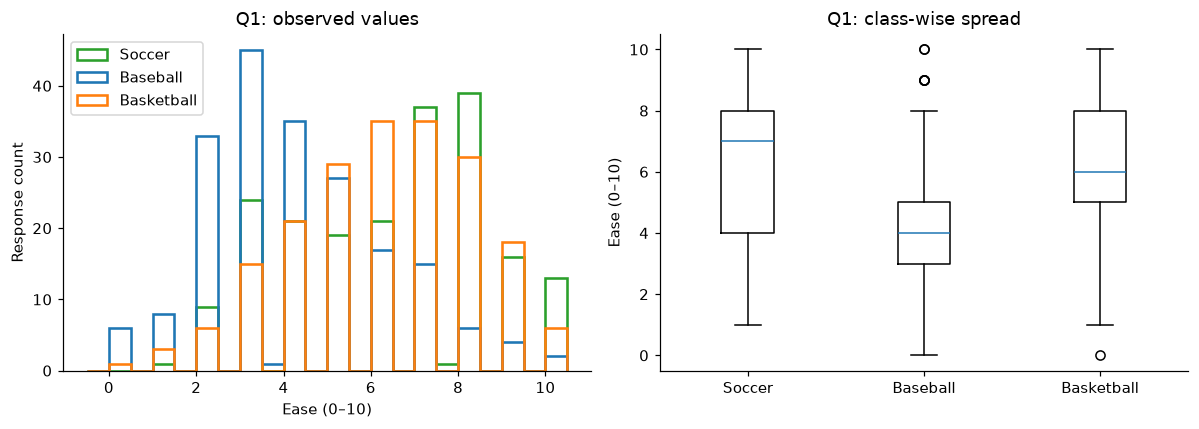

Noninteger valid responses: 2
Invalid/range violations: 0


Q1 class means range from **4.01 to 6.21**, with within-class SDs of **2.27, 2.06, 2.09**. Overlap in the distributions should be considered alongside these means; valid scale endpoints are retained.

In [7]:
q1_col = next(col for col in train if col.startswith('How easy'))
q1 = pd.to_numeric(train[q1_col].map(clean), errors='coerce').where(~missing_masks['Q1'])
def numeric_summary(values):
    groups = {'ALL': values, **{label: values[train.label == label] for label in CLASSES}}
    return pd.DataFrame({name: s.describe(percentiles=[.25,.5,.75,.95,.99]) for name,s in groups.items()}).T
q1_stats = numeric_summary(q1)
table(q1_stats, 'q1_summary')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label in CLASSES:
    axes[0].hist(q1[train.label == label].dropna(), bins=np.arange(-.5,11,.5), histtype='step', label=label, linewidth=1.7)
axes[0].set(xlabel='Ease (0–10)', ylabel='Response count', title='Q1: observed values')
axes[0].legend()
axes[1].boxplot([q1[train.label==label].dropna() for label in CLASSES], tick_labels=CLASSES)
axes[1].set(ylabel='Ease (0–10)', title='Q1: class-wise spread')
figure('q1_distribution')
print('Noninteger valid responses:', int((q1.dropna()%1 != 0).sum()))
print('Invalid/range violations:', int(quality.loc['Q1','invalid_n']))
display(Markdown('Q1 class means range from **{:.2f} to {:.2f}**, with within-class SDs of **{}**. Overlap in the distributions should be considered alongside these means; valid scale endpoints are retained.'.format(q1_stats.loc[CLASSES,'mean'].min(), q1_stats.loc[CLASSES,'mean'].max(), ', '.join(f'{x:.2f}' for x in q1_stats.loc[CLASSES,'std']))))

## 5. Q12: payment, parse failures and outliers
Use the same parser as the encoder, but analyze **only observed parsed amounts**, before mean replacement. Ranges use their midpoint, `k` means thousands, and currencies are assumed comparable without conversion. Upper-bound answers are treated as the stated amount. These simplifying assumptions can introduce measurement error.

Tukey's 1.5×IQR rule below is a descriptive flag, not an automatic deletion rule. Extreme payments may be genuine. A `log1p` view preserves zeros and makes the skew visible; no clipping or log transform is silently applied to encoded data.

,responses,pct
status,,
single_amount,510,84.158
no_numeric_amount,48,7.921
range_midpoint,36,5.941
blank,7,1.155
multiple_or_ambiguous_amounts,5,0.825


,count,mean,std,min,25%,50%,75%,95%,99%,max
ALL,546.0,275.721,744.176,0.0,50.0,100.0,250.0,1000.0,3000.0,10000.0
Soccer,181.0,407.914,1091.222,0.0,80.0,175.0,400.0,1000.0,4400.0,10000.0
Baseball,180.0,131.194,330.318,0.0,30.0,50.0,100.0,305.0,1420.0,3000.0
Basketball,185.0,287.005,575.802,0.0,90.0,150.0,300.0,960.0,2480.0,5000.0


IQR fences: -250.00, 550.00; flagged 46 / 546 parsed responses
Observed zeros: 49; skewness: 9.565


,answer,amount,status,label
84,$10 000,10000.0,single_amount,Soccer
63,"$10,000",10000.0,single_amount,Soccer
86,"$5,000",5000.0,single_amount,Basketball
422,5k,5000.0,single_amount,Basketball
381,$5000 to $1000,3000.0,range_midpoint,Soccer
85,"$3,000",3000.0,single_amount,Baseball
382,$5000 to $1000,3000.0,range_midpoint,Baseball
213,"$2000, (have done before)",2000.0,single_amount,Soccer
5,"$2,000",2000.0,single_amount,Basketball
233,2000,2000.0,single_amount,Basketball


,status,answer,count
0,no_numeric_amount,not really willing to,3
1,no_numeric_amount,Because I am not very interested in [this spor...,1
2,no_numeric_amount,None,2
3,multiple_or_ambiguous_amounts,"Usually around 100 to 200 CAD, but at most 100...",1
4,no_numeric_amount,No willing.,1
5,no_numeric_amount,Not willing,1
6,no_numeric_amount,Not willing.,1
7,no_numeric_amount,I would not pay to watch in person,1
8,no_numeric_amount,I would not pay for a [this sport] game,1
9,no_numeric_amount,I would not pay to watch this sport,1


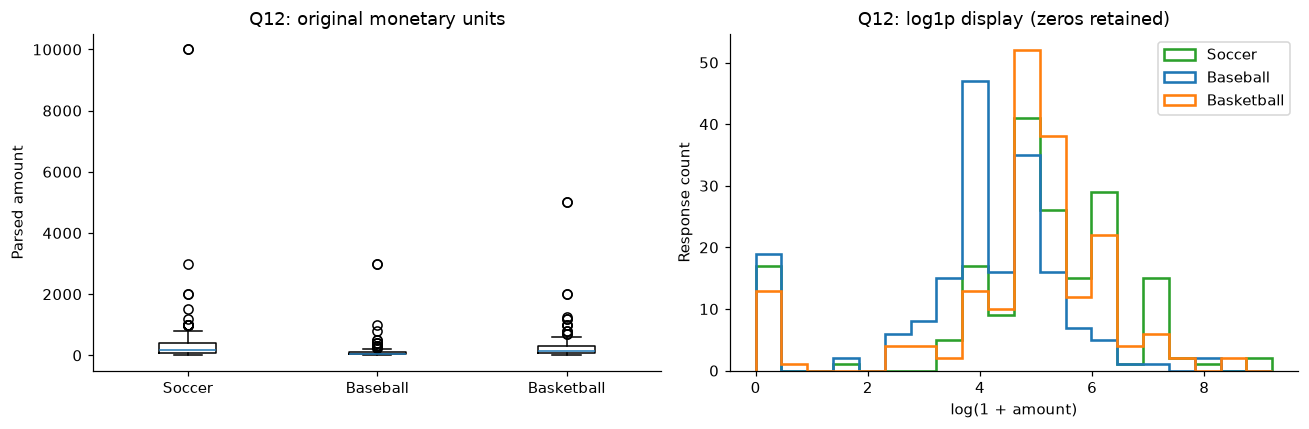

,replacement,missing_responses
current training mean,275.721,60
alternative training median,100.000,60


The observed median is **100.00**, mean **275.72**, and maximum **10,000.00**. **60 / 606 (9.9%)** require imputation. The large mean–median difference motivates considering a robust median and/or log1p representation during methodology. Current encoded artifacts retain the existing mean policy; no validation-based choice has been made.

In [8]:
q12_col = next(col for col in train if col.startswith('How much'))
parsed = train[q12_col].map(parse_payment)
payment = pd.Series([x[0] for x in parsed], index=train.index, dtype=float)
status = pd.Series([x[1] for x in parsed], index=train.index, name='status')
table(status.value_counts().to_frame('responses').assign(pct=lambda d: 100*d.responses/len(train)), 'payment_parse_status')
payment_stats = numeric_summary(payment)
table(payment_stats, 'payment_summary_observed')
q25, q75 = payment.quantile([.25,.75])
low, high = q25 - 1.5*(q75-q25), q75 + 1.5*(q75-q25)
flag = (payment < low) | (payment > high)
print(f'IQR fences: {low:.2f}, {high:.2f}; flagged {flag.sum()} / {payment.notna().sum()} parsed responses')
print(f'Observed zeros: {payment.eq(0).sum()}; skewness: {payment.skew():.3f}')
examples = pd.DataFrame({'answer': train[q12_col], 'amount': payment, 'status': status, 'label': train.label})
table(examples[flag].sort_values('amount', ascending=False).head(12), 'payment_extreme_examples')
table(examples[payment.isna()].groupby(['status','answer'], sort=False).size().rename('count').reset_index(), 'payment_unparsed_examples')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].boxplot([payment[train.label==label].dropna() for label in CLASSES], tick_labels=CLASSES)
axes[0].set(title='Q12: original monetary units', ylabel='Parsed amount')
for label in CLASSES:
    axes[1].hist(np.log1p(payment[train.label==label].dropna()), bins=np.linspace(0, np.log1p(payment.max()), 21), histtype='step', label=label, linewidth=1.7)
axes[1].set(title='Q12: log1p display (zeros retained)', xlabel='log(1 + amount)', ylabel='Response count')
axes[1].legend()
figure('q12_distribution')
assert np.isclose(payment.mean(), summary['payment_training_mean'])
comparison = pd.DataFrame({'replacement': [payment.mean(), payment.median()], 'missing_responses': [payment.isna().sum()]*2}, index=['current training mean','alternative training median'])
table(comparison, 'payment_imputation_comparison')
display(Markdown(f'The observed median is **{payment.median():.2f}**, mean **{payment.mean():.2f}**, and maximum **{payment.max():,.2f}**. **{payment.isna().sum()} / {len(train)} ({payment.isna().mean():.1%})** require imputation. The large mean–median difference motivates considering a robust median and/or log1p representation during methodology. Current encoded artifacts retain the existing mean policy; no validation-based choice has been made.'))

## 6. Existing text exploration plus usable-vector coverage
Reuse the original normalisation and counts for comparison. Its `rows_invalid` field is a semantic heuristic, not the encoder's missing flag; word counts include those answers. Document frequencies count responses containing a token once, unlike token counts which count repetitions. The original word-count normalizer and modelling TF-IDF tokeniser differ, so vocabulary sizes need not match.

For actual encoder coverage, inspect canonical **training** TF-IDF blocks below. A nonmissing response can still have an all-zero vector after alphabet filtering, minimum document frequency and vocabulary limits.

,question,column,rows_total,rows_blank,rows_invalid,rows_with_tokens,tokens_total,vocabulary_size,singleton_words,tokens_per_row,top_word,top_word_count
0,Q8 food and drinks,What foods and drinks do you associate with wa...,606,9,20,595,2766,445,265,4.649,and,213
1,Q9 colour,What colour do you associate with this sport?,606,7,8,597,1167,153,85,1.955,blue,157
2,Q10 song,Which song do you associate with this sport?,606,11,66,591,2449,562,337,4.144,waka,176
3,Q11 feeling,How do you feel when you watch this sport?,606,7,8,597,2575,599,343,4.313,excited,178
4,Q12 willingness to pay,How much would you be willing to pay for a dec...,606,7,13,599,1310,223,86,2.187,100,97


,question,word,n_rows_with_word_Soccer,n_rows_with_word_Baseball,n_rows_with_word_Basketball
448,Q9 colour,green,99,7,0
598,Q10 song,waka,89,0,0


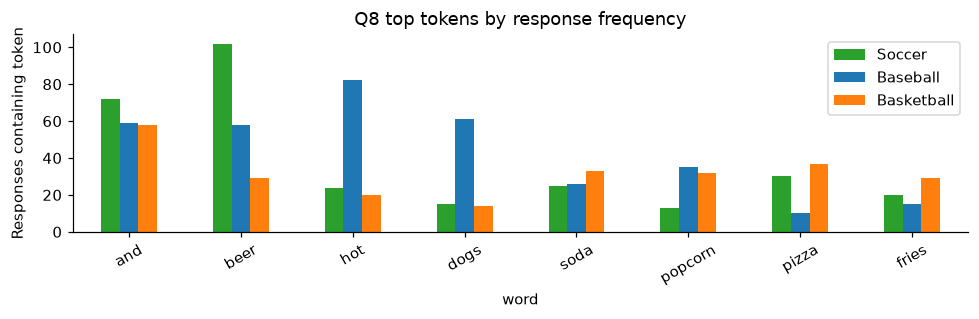

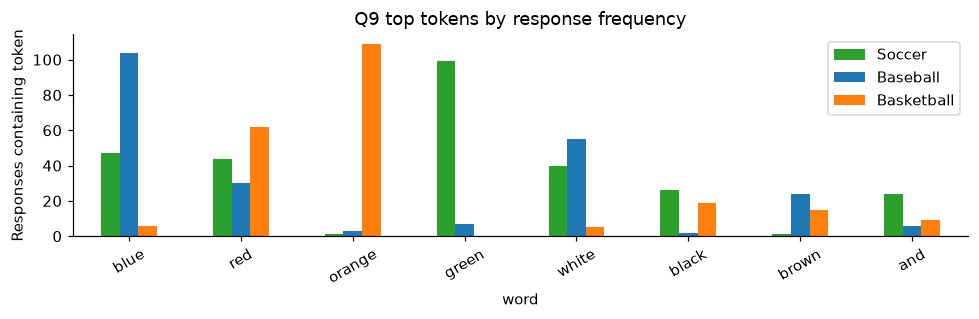

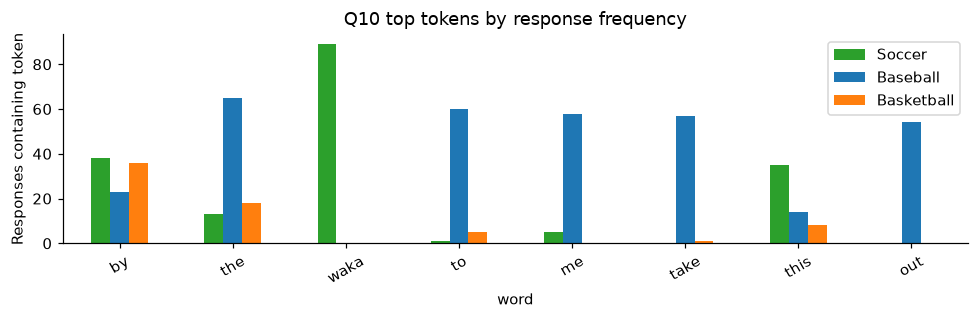

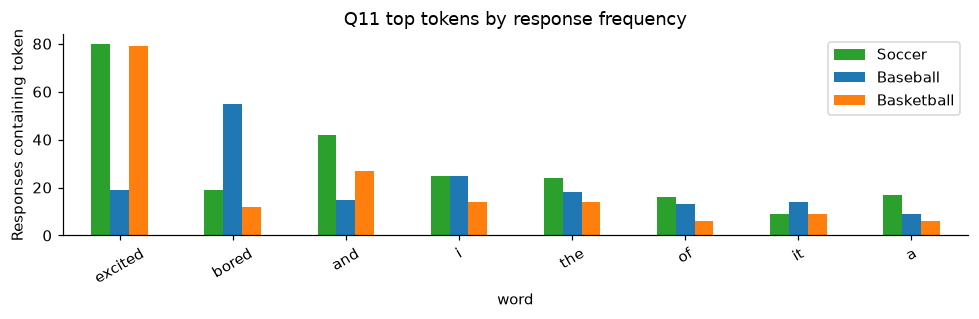

,field,retained_terms,missing_n,all_zero_n,nonmissing_all_zero_n
0,food,50,12,41,29
1,colour,20,7,28,21
2,song,50,32,162,130
3,feeling,50,7,115,108


In [9]:
word_rows, text_summary, _ = count_words(train)
words = pd.DataFrame(word_rows)
table(pd.DataFrame(text_summary), 'text_summary_legacy')
selected = words[((words.question.str.startswith('Q9')) & words.word.eq('green')) | ((words.question.str.startswith('Q10')) & words.word.eq('waka'))]
table(selected[['question','word']+[f'n_rows_with_word_{label}' for label in CLASSES]], 'text_signal_examples')
for q in ['Q8','Q9','Q10','Q11']:
    top = words[words.question.str.startswith(q)].nlargest(8,'n_rows_with_word').set_index('word')
    top[[f'n_rows_with_word_{label}' for label in CLASSES]].rename(columns={f'n_rows_with_word_{label}':label for label in CLASSES}).plot.bar(figsize=(9,3), title=q+' top tokens by response frequency', ylabel='Responses containing token', rot=30)
    figure(q.lower()+'_text_tokens')
encoded_train = pd.read_csv(ROOT/'data/encoded/train_encoded.csv')
coverage = []
for field in ['food','colour','song','feeling']:
    cols = [col for col in encoded_train if col.startswith(field+'_tfidf_')]
    zero = encoded_train[cols].eq(0).all(axis=1)
    missing = encoded_train[field+'_text_missing'].eq(1)
    coverage.append({'field':field, 'retained_terms':len(cols), 'missing_n':int(missing.sum()), 'all_zero_n':int(zero.sum()), 'nonmissing_all_zero_n':int((zero & ~missing).sum())})
table(pd.DataFrame(coverage), 'text_vector_coverage')

“Green” occurs in 99 Soccer, 7 Baseball and 0 Basketball responses; “waka” occurs in 89 Soccer responses and none of the other classes. These are plausible predictive signals. Song associations can depend on culture and cohort, so their reliability on staff responses is uncertain. The small respondent count and many sparse word features motivate regularization, not a claim that a particular vocabulary cap already has the best accuracy.

## 7. Remaining preparation checks and conclusions
Inspect numeric/ordinal correlations and nearly constant encoded columns using training only. Correlation does not by itself require deleting a feature. Derived selection counts in the exploratory plots are not currently part of the 201-column model encoding.

In [10]:
structured = encode_structured(train)
first4 = [next(col for col in structured if col.startswith(prefix)) for _,_,prefix,_ in QUALITY_SPECS[:4]]
corr = structured[first4].rename(columns=dict(zip(first4,['Q1','Q2','Q3','Q4']))).corr(method='spearman')
table(corr, 'ordinal_spearman_correlations')
features = encoded_train.drop(columns=['id','label'])
dominant_share = features.apply(lambda s: s.value_counts(normalize=True, dropna=True).max())
table(dominant_share[dominant_share >= .98].sort_values(ascending=False).to_frame('dominant_observed_value_share'), 'near_constant_features')
print('Feature count:', features.shape[1])
print('Remaining missing cells (Q1–Q7 intentionally not yet imputed):', int(features.isna().sum().sum()))
assert features.shape[1] == summary['feature_count']
assert features.isna().sum().sum() == summary['splits']['train']['remaining_missing_feature_cells']
print('Raw training responses:', len(train), '| independent respondent groups:', train.id.nunique())
print('All exploration and integrity checks completed; no model evaluation performed.')

,Q1,Q2,Q3,Q4
Q1,1.000,0.024,0.139,-0.058
Q2,0.024,1.000,0.338,-0.227
Q3,0.139,0.338,1.000,-0.128
Q4,-0.058,-0.227,-0.128,1.000


,dominant_observed_value_share
song_tfidf_dai,0.992
song_tfidf_la,0.990
song_tfidf_albert,0.988
colour_tfidf_gold,0.988
colour_tfidf_colour,0.988
colour_text_missing,0.988
feeling_text_missing,0.988
song_tfidf_tilzer,0.988
song_tfidf_von,0.988
song_tfidf_travis,0.988


Feature count: 201
Remaining missing cells (Q1–Q7 intentionally not yet imputed): 177
Raw training responses: 606 | independent respondent groups: 202
All exploration and integrity checks completed; no model evaluation performed.


### Report takeaways and handoff to methodology
- All 12 questions now have distribution/quality coverage. Q2–Q7 retain the team's existing analysis; Q1 and parsed Q12 now have numerical summaries and plots, and Q8–Q11 have text summaries and class-wise token plots.
- The class balance is exactly equal. Keep respondent grouping and exclude ID from inputs. Use only training-derived vocabulary, imputation and scaling parameters.
- Keep the current 0–1 ordinal and multi-hot representations documented separately from 1–5 exploratory scores. Text is TF-IDF with per-field caps, training-only IDF and L2 normalization; zero-vector coverage is quantified above. The full feature count is verified from the actual artifact, not assumed for future folds.
- Missingness definitions and parser limitations are explicit. Complete structured-feature imputation in the modelling pipeline before using models that cannot accept NaNs. Q12's skew and sensitivity to mean replacement motivate testing robust preprocessing; do not remove high payments just because they are large.
- Strong venue, season, music and word associations justify comparing linear and nonlinear classifiers. Marginal plots cannot prove nonlinear separability. Pairwise ordinal correlations and near-constant columns are reported rather than ignored.
- No model comparison, hyperparameter search, validation accuracy claim or hidden-test estimate is made in this notebook. The next task is a reproducible methodology plan with at least three model families, fair tuning and metrics beyond accuracy.

**Reproducibility:** run `python analysis/rebuild_encoded.py` only when rebuilding generated encodings, then Run All in this notebook. Do not use `encode_all.py --input` for this project partition. Existing exploratory scripts remain available; the notebook's encoder-aligned missingness tables supersede their older heuristic counts for reporting preprocessing availability.